# 02 · Comparing the configurations

All configurations are fitted at k = 4 and compared with one rule decided in advance: the Pairwise
Separability Index (PSI) on the same interpretation variables. The configuration with the highest PSI is
profiled in detail in notebook 03.

| ID | Feature space | Algorithm | Quantitative blocks (distance) | What it tests |
|---|---|---|---|---|
| C1 | Clinical | SampleDistClustering, Robust G-Gower | clinical (robust Mahalanobis) | clinical baseline |
| C1-b | Clinical | k-means | standardised clinical variables (Euclidean) | effect of the algorithm on the same features |
| C2 | Clinical + CDR | SampleDistClustering, Robust G-Gower | clinical + CDR (robust Mahalanobis) | severity as part of the profile |
| I1 | Images | SampleDistClustering, RelMS | 5 image blocks × 110 PCs (Euclidean) | image-only structure |
| I2 | Images | SampleDistClustering, G-Gower | 5 image blocks × 110 PCs (Euclidean) | RelMS vs. G-Gower on images |
| M1 | Images + clinical | SampleDistClustering, RelMS | 5 image blocks (Euclidean) + clinical (robust Mahalanobis) | added value of images |
| M2 | Images + clinical | SampleDistClustering, Robust G-Gower | same as M1 | same, with G-Gower |
| M3 | Images + clinical + CDR | SampleDistClustering, best of M1/M2 | 5 image blocks + clinical + CDR | full profile including severity |

Clinical variables: Age, MMSE, eTIV, nWBV, Education, SES. All configurations use the same 216 patients,
`frac_sample_size = 1` and the exact RelMS distance.

Interpretation variables: Age, MMSE, nWBV, eTIV, Education, SES, CDR (|Cliff's δ|) and sex (Total Variation
Distance).

Note when reading the table: a configuration tends to score higher on the variables it was clustered on. The
clinical configurations use six of the eight interpretation variables as inputs (C2 and M3 also CDR), while the
image-only configurations use none of them. The PSI therefore measures how clearly each configuration separates
patients on these clinical dimensions.

In [1]:
import json

%run -i ../src/setup.ipynb

K = cfg.K
OUT = cfg.RESULTS_DIR / "02_compare_configurations"
OUT.mkdir(parents=True, exist_ok=True)
df = load_analysis_data()
print(f"k = {K}, patients = {len(df)}, results in {OUT.relative_to(ROOT)}")

k = 4, patients = 216, results in results\02_compare_configurations


## 1. Fitting the configurations

Cluster 1 is the cluster with the highest mean MMSE.

In [2]:
results = {}
for name in ["C1", "C1-b", "C2", "I1", "I2", "M1", "M2"]:
    r = fit_configuration(name, K, df)
    r["labels"] = relabel_by(df, r["labels"], "MMSE")
    results[name] = r
    print(f"{name:5s} sizes: {np.bincount(r['labels'])[1:].tolist()}")

C1    sizes: [34, 61, 65, 56]


C1-b  sizes: [47, 72, 67, 30]
C2    sizes: [37, 61, 69, 49]


I1    sizes: [40, 60, 61, 55]
I2    sizes: [57, 78, 66, 15]


M1    sizes: [38, 53, 60, 65]
M2    sizes: [71, 25, 50, 70]


## 2. Distance for M3

M3 adds CDR to the clinical block of whichever of M1 (RelMS) and M2 (G-Gower) has the higher PSI.

In [3]:
psi_m1 = psi_column(df, results["M1"]["labels"], "M1")["PSI (mean)"]
psi_m2 = psi_column(df, results["M2"]["labels"], "M2")["PSI (mean)"]
m3_metric = "relms" if psi_m1 >= psi_m2 else "ggower"
print(f"PSI M1 (RelMS) = {psi_m1:.3f}   PSI M2 (G-Gower) = {psi_m2:.3f}   ->  M3 uses {m3_metric}")

r = fit_configuration("M3", K, df, metric=m3_metric)
r["labels"] = relabel_by(df, r["labels"], "MMSE")
results["M3"] = r
print(f"M3    sizes: {np.bincount(r['labels'])[1:].tolist()}")

PSI M1 (RelMS) = 0.287   PSI M2 (G-Gower) = 0.340   ->  M3 uses ggower
M3    sizes: [70, 26, 53, 67]


## 3. PSI table

Per-variable PSI (mean over the 6 pairs of clusters) and the aggregate PSI (mean over the 8 variables).
N = negligible (< 0.147), S = small, M = medium (≥ 0.33), L = large (≥ 0.474). The highest value of each row is
in bold.

In [4]:
ORDER = ["C1", "C1-b", "C2", "I1", "I2", "M1", "M2", "M3"]
psi = pd.concat([psi_column(df, results[n]["labels"], n) for n in ORDER], axis=1)
psi.to_csv(OUT / "psi_table.csv")

def bold_row_max(row):
    return ["font-weight: bold" if v == row.max() else "" for v in row]

labelled = format_psi_table(psi)
display(labelled.style.apply(lambda r: bold_row_max(psi.loc[r.name]), axis=1))

,C1,C1-b,C2,I1,I2,M1,M2,M3
Age,0.656 (L),0.592 (L),0.623 (L),0.263 (S),0.300 (S),0.370 (M),0.306 (S),0.338 (M)
MMSE,0.484 (L),0.662 (L),0.410 (M),0.137 (N),0.213 (S),0.244 (S),0.258 (S),0.296 (S)
nWBV,0.704 (L),0.760 (L),0.625 (L),0.318 (S),0.364 (M),0.418 (M),0.481 (L),0.501 (L)
eTIV,0.254 (S),0.241 (S),0.287 (S),0.296 (S),0.223 (S),0.265 (S),0.526 (L),0.511 (L)
Educ,0.459 (M),0.683 (L),0.356 (M),0.043 (N),0.131 (N),0.230 (S),0.320 (S),0.265 (S)
SES,0.370 (M),0.606 (L),0.337 (M),0.060 (N),0.126 (N),0.328 (S),0.296 (S),0.268 (S)
CDR,0.434 (M),0.577 (L),0.546 (L),0.134 (N),0.154 (S),0.240 (S),0.182 (S),0.245 (S)
sex,0.160 (S),0.094 (N),0.166 (S),0.275 (S),0.132 (N),0.200 (S),0.347 (M),0.334 (M)
PSI (mean),0.440 (M),0.527 (L),0.419 (M),0.191 (S),0.205 (S),0.287 (S),0.340 (M),0.345 (M)


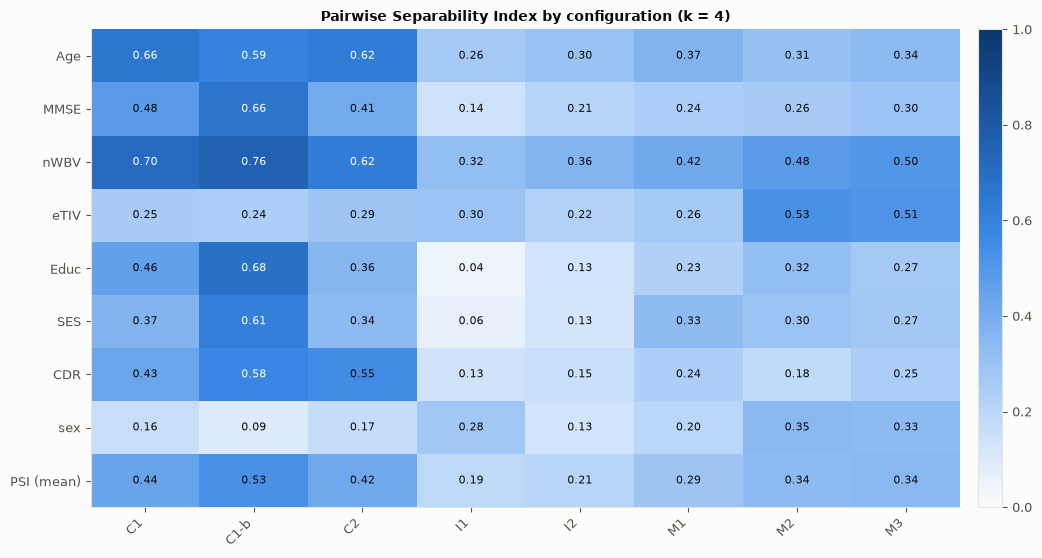

1136

In [5]:
fig = psi_heatmap(psi, f"Pairwise Separability Index by configuration (k = {K})")
fig.savefig(OUT / "psi_table_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

latex = labelled.copy()
for var in psi.index:
    best = psi.loc[var].idxmax()
    latex.loc[var, best] = r"\textbf{" + latex.loc[var, best] + "}"
(OUT / "psi_table.tex").write_text(latex.to_latex(escape=False), encoding="utf-8")

## 4. Selection

The configuration with the highest aggregate PSI is selected.

In [6]:
ranking = psi.loc["PSI (mean)"].sort_values(ascending=False)
display(ranking.round(3).to_frame("aggregate PSI"))
selected = ranking.index[0]
print(f"Selected configuration: {selected} (PSI = {ranking.iloc[0]:.3f})")

(OUT / "selection.json").write_text(json.dumps({
    "k": K, "selected": selected, "m3_metric": m3_metric,
    "aggregate_psi": ranking.round(4).to_dict(),
}, indent=2), encoding="utf-8")

labels = pd.DataFrame({n: results[n]["labels"] for n in ORDER})
labels.insert(0, "patient_id", df["patient_id"])
labels.to_csv(OUT / "labels.csv", index=False)

,aggregate PSI
C1-b,0.527
C1,0.440
C2,0.419
M3,0.345
M2,0.340
M1,0.287
I2,0.205
I1,0.191


Selected configuration: C1-b (PSI = 0.527)


## 5. Summary of each configuration

Cluster medians, the share of patients with CDR > 0 and the share of men.

In [7]:
def cluster_summary(labels):
    g = df.assign(cluster=labels).groupby("cluster")
    t = g.agg(n=("Age", "size"), Age=("Age", "median"), MMSE=("MMSE", "median"), nWBV=("nWBV", "median"),
              eTIV=("eTIV", "median"), Educ=("Educ", "median"), SES=("SES", "median"))
    t["CDR>0 (%)"] = g["CDR"].apply(lambda s: 100 * (s > 0).mean()).round(0)
    t["men (%)"] = (100 * g["sex"].mean()).round(0)
    return t

summaries = []
for n in ORDER:
    t = cluster_summary(results[n]["labels"]).round(3)
    print(f"\n{n}  (PSI = {psi.loc['PSI (mean)', n]:.3f})")
    display(t)
    summaries.append(t.assign(config=n).reset_index())
pd.concat(summaries).to_csv(OUT / "cluster_summaries.csv", index=False)


C1  (PSI = 0.440)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,34,52.0,30.0,0.814,1373.0,4.0,2.0,0.0,21.0
2,61,80.0,29.0,0.727,1398.0,4.0,2.0,30.0,21.0
3,65,72.0,29.0,0.773,1495.0,3.0,3.0,29.0,48.0
4,56,75.0,23.0,0.715,1461.5,2.0,3.0,82.0,36.0



C1-b  (PSI = 0.527)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,47,54.0,30.0,0.814,1389.0,4.0,2.0,0.0,28.0
2,72,73.5,29.0,0.764,1391.0,2.0,3.0,31.0,26.0
3,67,78.0,28.0,0.730,1534.0,5.0,1.0,48.0,43.0
4,30,78.0,21.0,0.693,1461.0,2.0,4.0,97.0,33.0



C2  (PSI = 0.419)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,37,52.0,30.0,0.814,1373.0,4.0,2.0,0.0,19.0
2,61,80.0,29.0,0.727,1388.0,4.0,2.0,25.0,21.0
3,69,73.0,29.0,0.767,1486.0,3.0,3.0,28.0,46.0
4,49,78.0,27.0,0.716,1465.0,2.0,3.0,100.0,39.0


... (6 outputs left out)


M2  (PSI = 0.340)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,71,66.0,29.0,0.789,1420.0,3.0,3.0,23.0,28.0
2,25,75.0,29.0,0.736,1750.0,5.0,2.0,36.0,84.0
3,50,79.5,28.0,0.707,1454.5,4.0,3.0,54.0,36.0
4,70,77.0,28.0,0.742,1384.0,3.0,2.0,44.0,17.0



M3  (PSI = 0.345)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,70,64.5,30.0,0.790,1411.0,3.0,3.0,17.0,29.0
2,26,76.0,29.0,0.736,1742.0,5.0,2.0,35.0,81.0
3,53,78.0,28.0,0.708,1455.0,4.0,3.0,58.0,36.0
4,67,78.0,28.0,0.742,1384.0,3.0,2.0,46.0,16.0


## 6. Cluster profiles of every configuration

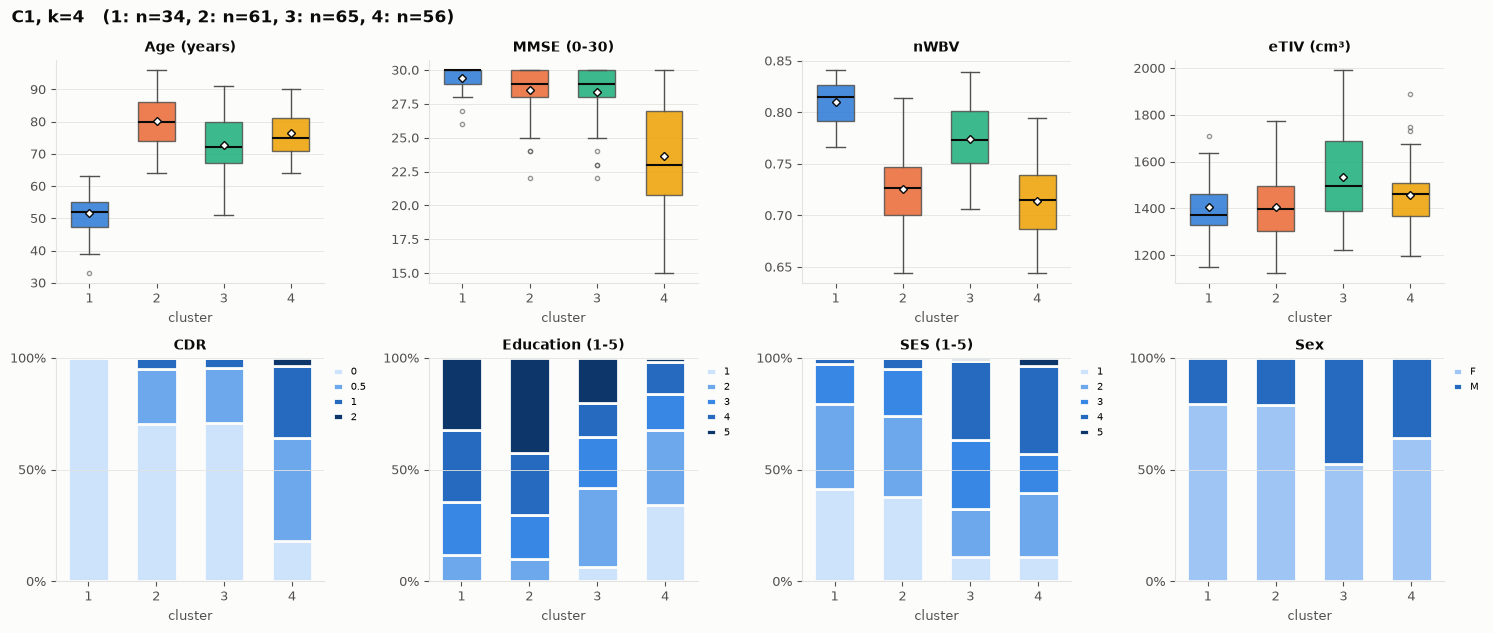

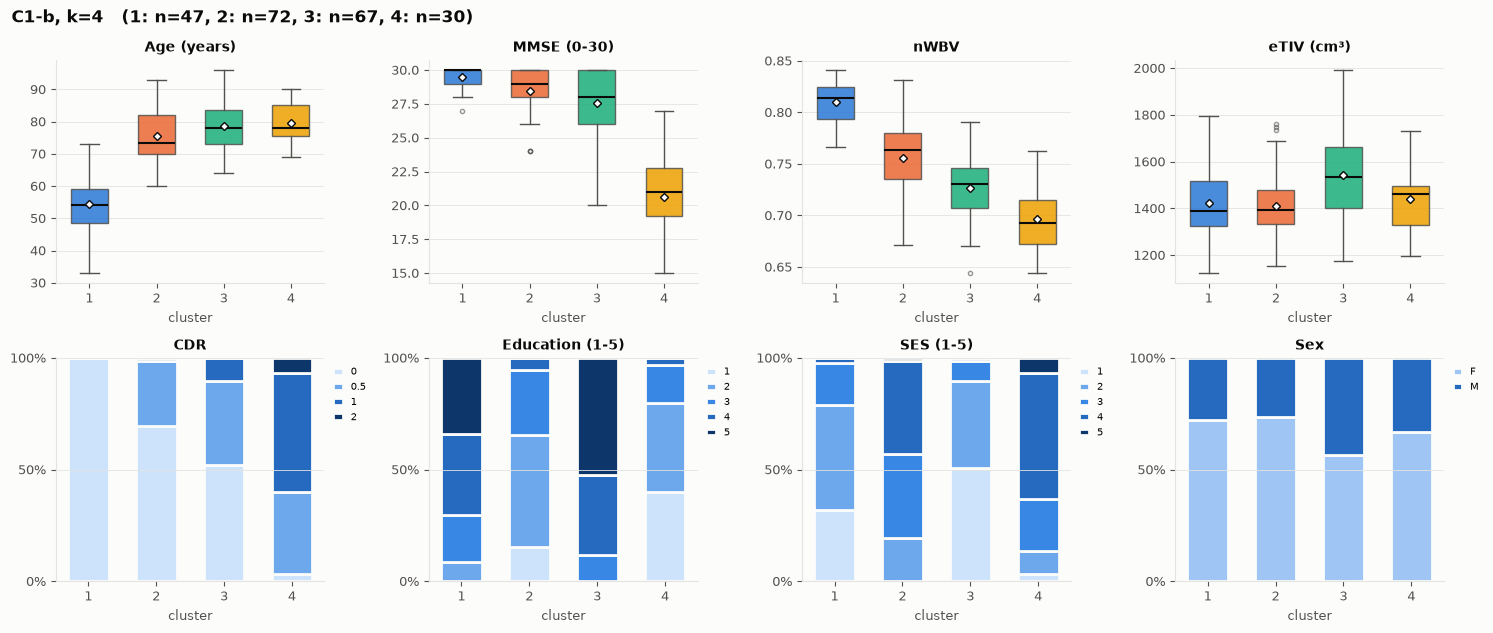

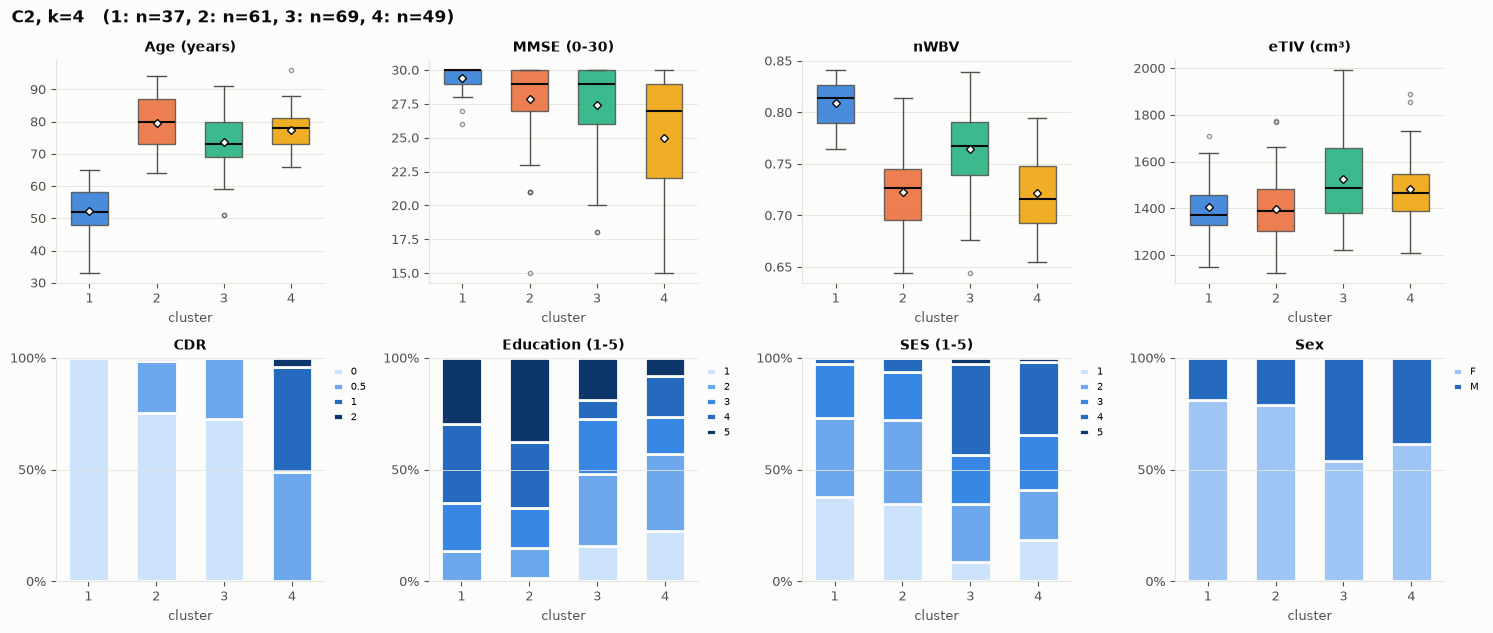

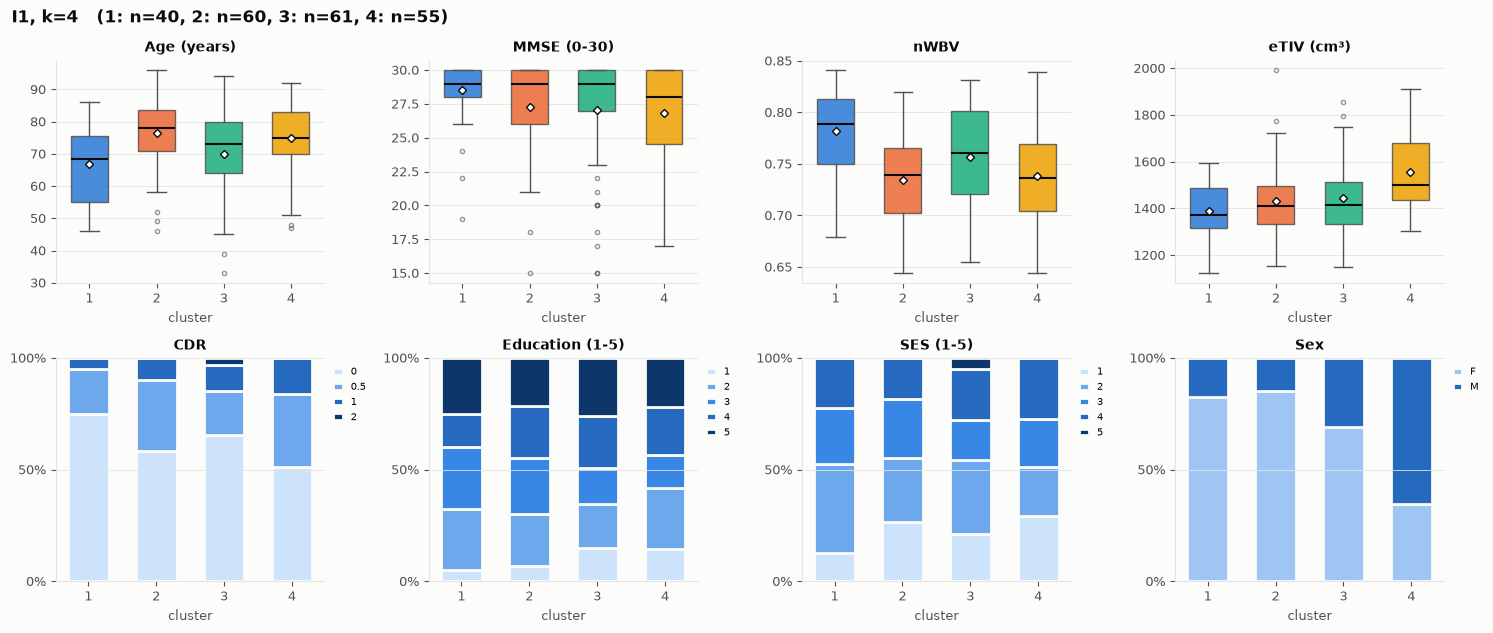

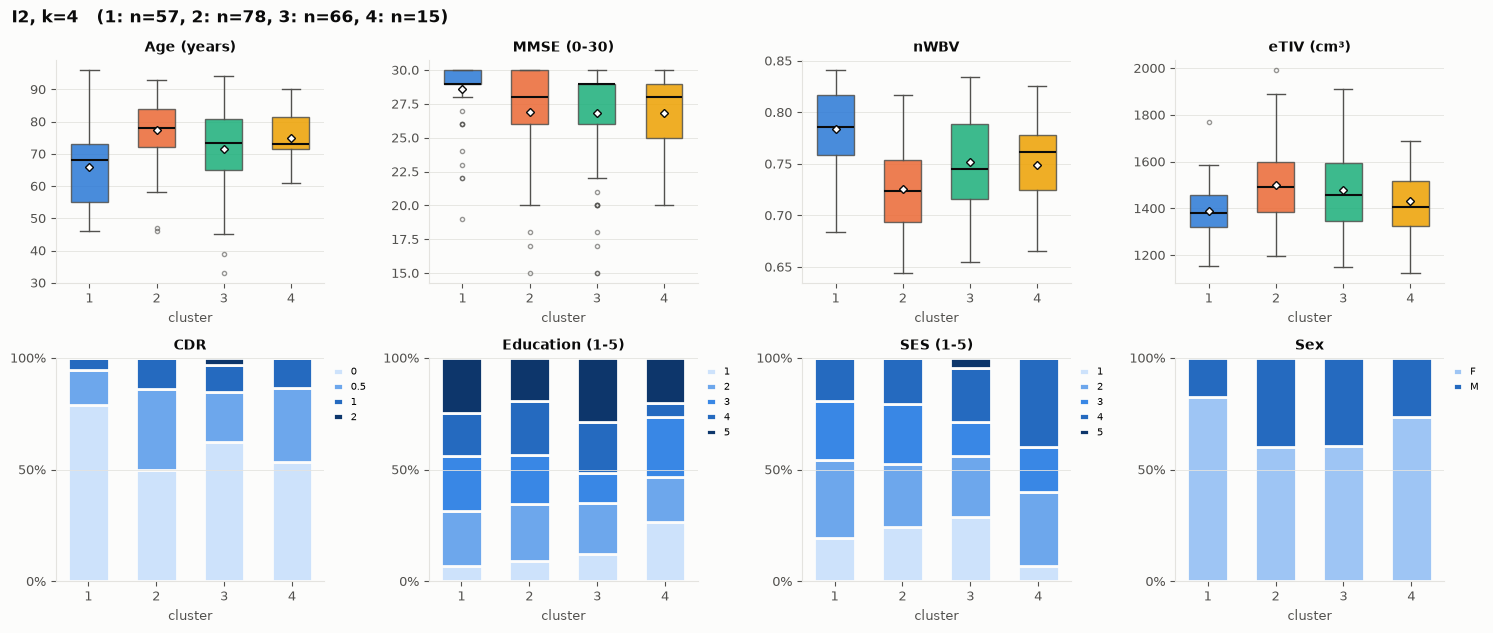

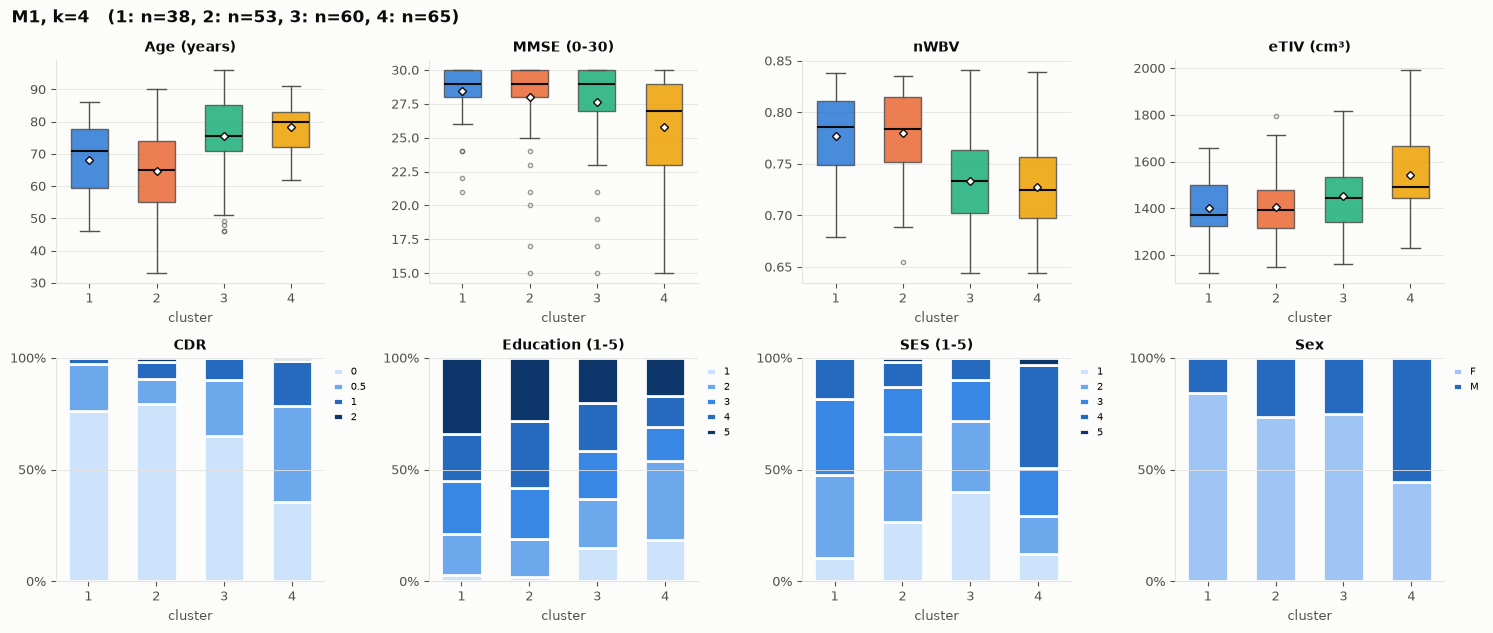

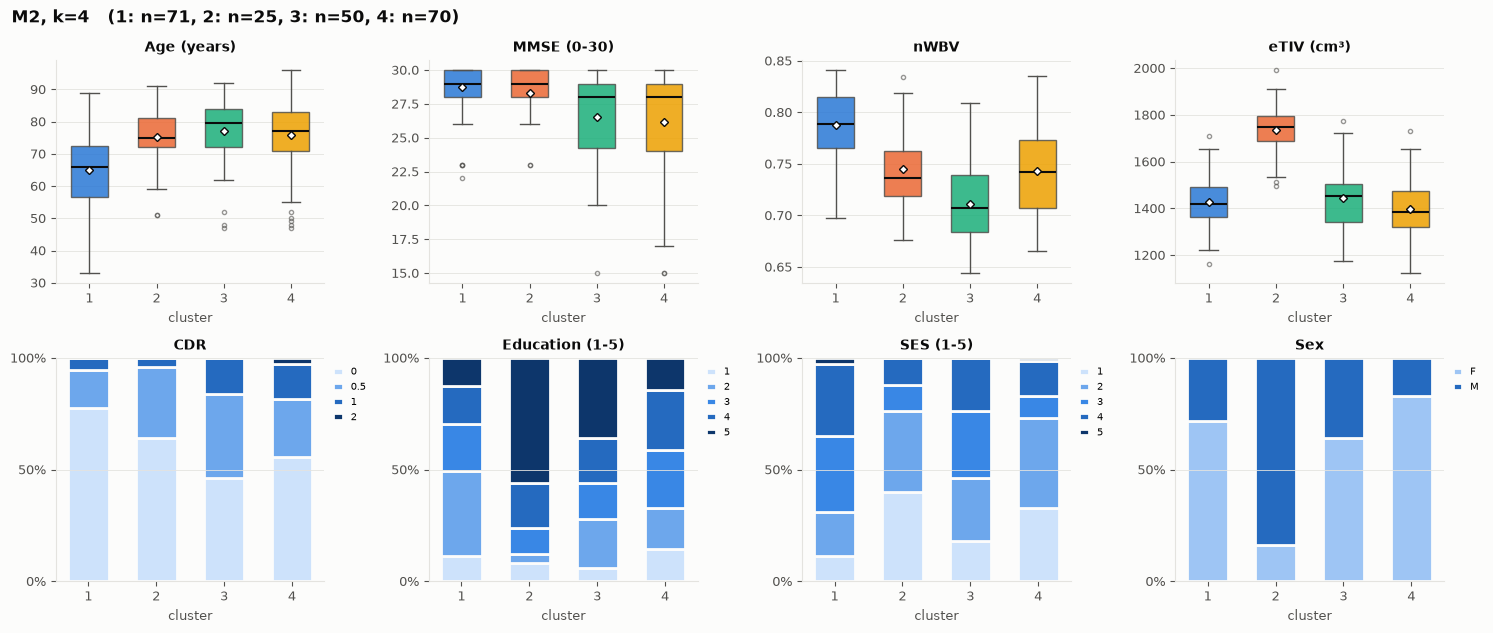

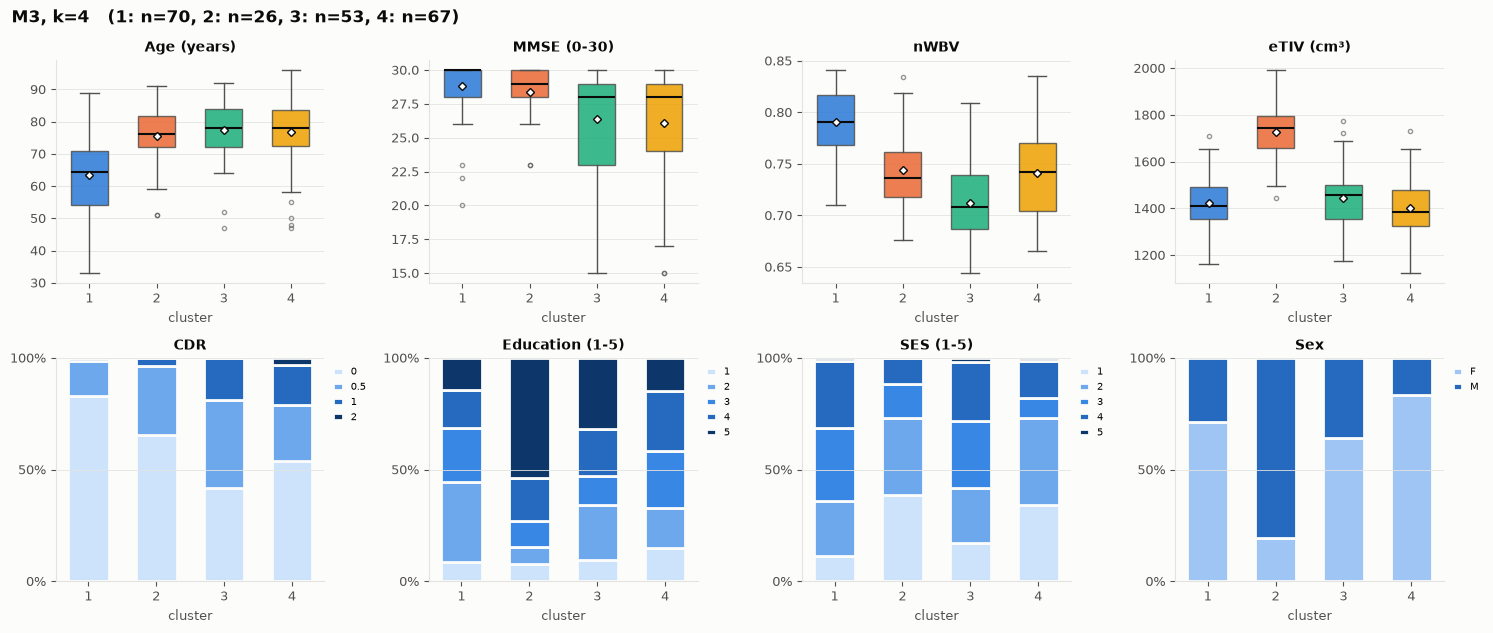

In [8]:
for n in ORDER:
    fig = cluster_profile(df, results[n]["labels"], f"{n}, k={K}")
    fig.savefig(OUT / f"profile_{n}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 7. Medoid patients

C1-b uses k-means, whose centroids are not real patients, so it has no medoids.

In [9]:
for n in ORDER:
    r = results[n]
    if r["medoids"] is None:
        continue
    print(f"\n{n}")
    display(medoid_table(df, r["labels"], r["medoids"]))


C1


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,34,OAS1_0044,F,47,30.0,0.0,0.829,1346,4.0,2.0
1,2,61,OAS1_0244,F,80,29.0,0.0,0.737,1341,4.0,2.0
2,3,65,OAS1_0139,F,72,28.0,0.0,0.779,1512,3.0,3.0
3,4,56,OAS1_0268,M,78,23.0,1.0,0.715,1491,2.0,3.0



C2


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,37,OAS1_0044,F,47,30.0,0.0,0.829,1346,4.0,2.0
1,2,61,OAS1_0244,F,80,29.0,0.0,0.737,1341,4.0,2.0
2,3,69,OAS1_0139,F,72,28.0,0.0,0.779,1512,3.0,3.0
3,4,49,OAS1_0268,M,78,23.0,1.0,0.715,1491,2.0,3.0



I1


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,40,OAS1_0109,F,61,30.0,0.0,0.813,1313,4.0,3.0
1,2,60,OAS1_0217,F,78,27.0,0.5,0.692,1393,4.0,3.0
2,3,61,OAS1_0308,F,78,15.0,2.0,0.703,1401,3.0,3.0
3,4,55,OAS1_0016,M,82,27.0,0.5,0.739,1477,2.0,4.0


... (4 outputs left out)


M2


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,71,OAS1_0341,F,71,30.0,0.0,0.772,1479,2.0,4.0
1,2,25,OAS1_0365,M,74,30.0,0.0,0.754,1806,5.0,2.0
2,3,50,OAS1_0217,F,78,27.0,0.5,0.692,1393,4.0,3.0
3,4,70,OAS1_0272,F,75,26.0,0.5,0.745,1355,3.0,2.0



M3


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,70,OAS1_0341,F,71,30.0,0.0,0.772,1479,2.0,4.0
1,2,26,OAS1_0365,M,74,30.0,0.0,0.754,1806,5.0,2.0
2,3,53,OAS1_0217,F,78,27.0,0.5,0.692,1393,4.0,3.0
3,4,67,OAS1_0272,F,75,26.0,0.5,0.745,1355,3.0,2.0
